<a href="https://colab.research.google.com/github/Simpson69-il/DEEPLEARNING5THSEM/blob/main/SELF_LEARNING/DL_SelfLearning_24BAD074.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 24ADI306 Deep Learning – Self Learning Assignment (CO3)
**Topic:** Exploring Word Representations: From Traditional Word Embeddings to Transformers

**Name:** Mohd Shafique R B  |  **Roll No:** 24BAD074  |  **Department:** AI & Data Science

Run all cells top to bottom (Runtime → Run all). Take screenshots of the outputs marked 📸.

## 0. Setup

In [1]:
!pip install -q gensim transformers torch scikit-learn matplotlib pandas
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
print('Name: Mohd Shafique R B | Roll No: 24BAD074')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 48.5 MB/s eta 0:00:00
Name: Mohd Shafique R B | Roll No: 24BAD074


## 1. Common dataset (20 Newsgroups – 4 categories)

In [2]:
cats = ['sci.space','rec.sport.hockey','comp.graphics','sci.med']
data = fetch_20newsgroups(subset='train', categories=cats, remove=('headers','footers','quotes'))
docs, labels = data.data, data.target
def tok(t): return [w for w in re.findall(r'[a-z]+', t.lower()) if len(w) > 2]
tokens = [tok(d) for d in docs]
tokens_ns = [[w for w in s if w not in ENGLISH_STOP_WORDS] for s in tokens]  # without stopwords
print(len(docs), 'documents;', sum(len(s) for s in tokens_ns), 'tokens')
print(docs[0][:300])

2371 documents; 221786 tokens
: I'm not sure if this is the correct place to ask this question.  If not,
: please forgive me and point me in the right direction.

: Does anybody know of a program that converts .GIF files to .BMP files
: and if so, where can I ftp it from?  Any help would be greatly 
: appreciated.

: Please resp


## 2. Traditional representations: One-Hot, BoW, TF-IDF
Simple demo on a tiny corpus first, then TF-IDF on the full dataset.

In [3]:
mini = ['the rocket reached orbit', 'the player scored a goal', 'the rocket launch was delayed']
bow = CountVectorizer().fit(mini)
print('Vocabulary:', bow.get_feature_names_out())
print('BoW:\n', bow.transform(mini).toarray())
tf_mini = TfidfVectorizer().fit(mini)
print('TF-IDF:\n', np.round(tf_mini.transform(mini).toarray(), 2))
vocab = list(bow.get_feature_names_out())
print('One-hot for "rocket":', [int(w=='rocket') for w in vocab])
bi = CountVectorizer(ngram_range=(1,2)).fit(mini)
print('Unigrams+bigrams:', bi.get_feature_names_out())

Vocabulary: ['delayed' 'goal' 'launch' 'orbit' 'player' 'reached' 'rocket' 'scored'
 'the' 'was']
BoW:
 [[0 0 0 1 0 1 1 0 1 0]
 [0 1 0 0 1 0 0 1 1 0]
 [1 0 1 0 0 0 1 0 1 1]]
TF-IDF:
 [[0.   0.   0.   0.58 0.   0.58 0.44 0.   0.35 0.  ]
 [0.   0.55 0.   0.   0.55 0.   0.   0.55 0.32 0.  ]
 [0.5  0.   0.5  0.   0.   0.   0.38 0.   0.3  0.5 ]]
One-hot for "rocket": [0, 0, 0, 0, 0, 0, 1, 0, 0, 0]
Unigrams+bigrams: ['delayed' 'goal' 'launch' 'launch was' 'orbit' 'player' 'player scored'
 'reached' 'reached orbit' 'rocket' 'rocket launch' 'rocket reached'
 'scored' 'scored goal' 'the' 'the player' 'the rocket' 'was'
 'was delayed']


In [4]:
tfidf = TfidfVectorizer(min_df=5, max_features=5000, stop_words='english')
X = tfidf.fit_transform(docs)            # docs x terms
terms = tfidf.get_feature_names_out()
term_vecs = X.T.tocsr()                   # each word = its TF-IDF column across documents
print('TF-IDF matrix shape:', X.shape)

def similar_tfidf(word, n=5):
    i = list(terms).index(word)
    s = cosine_similarity(term_vecs[i], term_vecs).ravel()
    idx = s.argsort()[::-1][1:n+1]
    return [(terms[j], round(float(s[j]),3)) for j in idx]

TF-IDF matrix shape: (2371, 5000)


## 3. Word2Vec (Skip-gram) with Gensim

In [5]:
from gensim.models import Word2Vec, FastText
w2v = Word2Vec(tokens_ns, vector_size=100, window=5, min_count=5, sg=1, epochs=30, workers=2, seed=42)
print('Vocab size:', len(w2v.wv))
queries = [w for w in ['space','hockey','graphics','doctor','image','team'] if w in w2v.wv]
for q in queries:
    print(q, '->', [(w, round(s,3)) for w,s in w2v.wv.most_similar(q, topn=5)])

Vocab size: 7252
space -> [('activist', 0.579), ('seds', 0.579), ('gothamcity', 0.548), ('kjenks', 0.539), ('planetary', 0.529)]
hockey -> [('leagues', 0.633), ('ncaa', 0.626), ('sport', 0.613), ('gulls', 0.588), ('league', 0.588)]
graphics -> [('exponent', 0.697), ('gems', 0.69), ('fbm', 0.656), ('vogle', 0.652), ('gnuplot', 0.649)]
doctor -> [('prescription', 0.656), ('elaine', 0.607), ('angry', 0.606), ('prescribed', 0.596), ('recurring', 0.588)]
image -> [('images', 0.67), ('processing', 0.67), ('enhancement', 0.646), ('manipulation', 0.607), ('transformations', 0.591)]
team -> [('assat', 0.577), ('mvp', 0.56), ('junior', 0.552), ('nets', 0.544), ('franchises', 0.539)]


In [6]:
# Analogy-style relationship (only if words are in vocab)
try:
    print(w2v.wv.most_similar(positive=['nasa','hockey'], negative=['space'], topn=5))
except KeyError as e:
    print('Word not in vocab:', e)

[('sport', 0.5152500867843628), ('junior', 0.46909070014953613), ('awesome', 0.4533478319644928), ('ncaa', 0.4431612193584442), ('league', 0.44151872396469116)]


## 4. FastText and out-of-vocabulary (OOV) handling

In [7]:
ft = FastText(tokens_ns, vector_size=100, window=5, min_count=5, sg=1, epochs=30, workers=2, seed=42)
oov = 'spaceships'   # rare/unseen form
print('In Word2Vec vocab?', oov in w2v.wv, '| In FastText vocab?', oov in ft.wv.key_to_index)
try: w2v.wv[oov]
except KeyError: print('Word2Vec -> KeyError (cannot represent OOV word)')
print('FastText still gives a vector, shape:', ft.wv[oov].shape)
print('FastText neighbours of', oov, ':', ft.wv.most_similar(oov, topn=5))

In Word2Vec vocab? False | In FastText vocab? False
Word2Vec -> KeyError (cannot represent OOV word)
FastText still gives a vector, shape: (100,)
FastText neighbours of spaceships : [('spacepac', 0.8034112453460693), ('spacehab', 0.7967240214347839), ('spacelink', 0.771632194519043), ('spacelab', 0.7671520709991455), ('fellowships', 0.7598651051521301)]


## 5. Neural embeddings with TensorFlow / Keras Embedding layer

In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
texts = [' '.join(s) for s in tokens_ns]
kt = Tokenizer(num_words=10000, oov_token='<OOV>'); kt.fit_on_texts(texts)
seqs = pad_sequences(kt.texts_to_sequences(texts), maxlen=200)
model = models.Sequential([
    layers.Embedding(10000, 50, name='embedding'),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation='relu'),
    layers.Dense(len(cats), activation='softmax')])
model.compile('adam', 'sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(seqs, labels, epochs=15, batch_size=32, validation_split=0.2, verbose=2)
model.summary()

Epoch 1/15
60/60 - 2s - 35ms/step - accuracy: 0.3107 - loss: 1.3830 - val_accuracy: 0.4105 - val_loss: 1.3677
Epoch 2/15
60/60 - 1s - 11ms/step - accuracy: 0.4030 - loss: 1.3480 - val_accuracy: 0.6716 - val_loss: 1.3076
Epoch 3/15
60/60 - 1s - 11ms/step - accuracy: 0.5074 - loss: 1.2642 - val_accuracy: 0.6274 - val_loss: 1.1830
Epoch 4/15
60/60 - 1s - 11ms/step - accuracy: 0.5955 - loss: 1.1155 - val_accuracy: 0.5116 - val_loss: 1.0611
Epoch 5/15
60/60 - 1s - 11ms/step - accuracy: 0.6614 - loss: 0.9608 - val_accuracy: 0.6758 - val_loss: 0.8871
Epoch 6/15
60/60 - 1s - 11ms/step - accuracy: 0.7157 - loss: 0.8272 - val_accuracy: 0.6779 - val_loss: 0.8376
Epoch 7/15
60/60 - 1s - 20ms/step - accuracy: 0.8017 - loss: 0.6952 - val_accuracy: 0.7053 - val_loss: 0.7635
Epoch 8/15
60/60 - 1s - 11ms/step - accuracy: 0.7890 - loss: 0.6498 - val_accuracy: 0.7432 - val_loss: 0.6965
Epoch 9/15
60/60 - 1s - 12ms/step - accuracy: 0.8618 - loss: 0.5247 - val_accuracy: 0.7916 - val_loss: 0.6053
Epoch 10/1

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 50)        │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 50)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,505,294 (5.74 MB)

 Trainable params: 501,764 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,003,530 (3.83 MB)

In [9]:
E = model.get_layer('embedding').get_weights()[0]
inv = {i:w for w,i in kt.word_index.items() if i < 10000}
def similar_keras(word, n=5):
    i = kt.word_index[word]
    s = cosine_similarity(E[i:i+1], E[1:]).ravel()
    idx = s.argsort()[::-1][1:n+1]
    return [(inv[j+1], round(float(s[j]),3)) for j in idx]
for q in queries: print(q, '->', similar_keras(q))

space -> [('launch', 0.998), ('gravity', 0.996), ('flight', 0.995), ('solar', 0.995), ('mission', 0.995)]
hockey -> [('leafs', 0.998), ('coach', 0.998), ('playoffs', 0.998), ('espn', 0.998), ('pens', 0.998)]
graphics -> [('vga', 0.998), ('tiff', 0.998), ('polygon', 0.997), ('vesa', 0.997), ('windows', 0.997)]
doctor -> [('cadre', 0.997), ('pain', 0.997), ('skepticism', 0.997), ('banks', 0.997), ('jxp', 0.997)]
image -> [('computer', 0.996), ('file', 0.995), ('graphics', 0.993), ('virtual', 0.993), ('color', 0.992)]
team -> [('canada', 0.995), ('win', 0.995), ('captain', 0.995), ('game', 0.994), ('sport', 0.994)]


## 6. Cosine-similarity comparison: TF-IDF vs Word2Vec vs Keras (top-5 neighbours)

In [10]:
rows=[]
for q in queries:
    if q in terms:
        rows.append({'Query':q,
          'TF-IDF':', '.join(w for w,_ in similar_tfidf(q)),
          'Word2Vec':', '.join(w for w,_ in w2v.wv.most_similar(q, topn=5)),
          'Keras Emb.':', '.join(w for w,_ in similar_keras(q))})
pd.set_option('display.max_colwidth', 80)
display(pd.DataFrame(rows))   # 📸 screenshot

,Query,TF-IDF,Word2Vec,Keras Emb.
0,space,"nasa, shuttle, station, sci, exploration","activist, seds, gothamcity, kjenks, planetary","launch, gravity, flight, solar, mission"
1,hockey,"ncaa, game, league, players, sport","leagues, ncaa, sport, gulls, league","leafs, coach, playoffs, espn, pens"
2,graphics,"comp, programmer, programming, 3d, computer","exponent, gems, fbm, vogle, gnuplot","vga, tiff, polygon, vesa, windows"
3,doctor,"clinic, room, told, upset, emergency","prescription, elaine, angry, prescribed, recurring","cadre, pain, skepticism, banks, jxp"
4,image,"processing, images, buffer, allows, permission","images, processing, enhancement, manipulation, transformations","computer, file, graphics, virtual, color"
5,team,"nhl, player, players, teams, coach","assat, mvp, junior, nets, franchises","canada, win, captain, game, sport"


## 7. Contextual embeddings with BERT (static vs contextual)

In [11]:
import torch
from transformers import AutoTokenizer, AutoModel
btok = AutoTokenizer.from_pretrained('bert-base-uncased')
bert = AutoModel.from_pretrained('bert-base-uncased').eval()
def word_vec(sentence, word):
    enc = btok(sentence, return_tensors='pt')
    with torch.no_grad(): out = bert(**enc).last_hidden_state[0]
    toks = btok.convert_ids_to_tokens(enc['input_ids'][0])
    return out[toks.index(word)].numpy()
s1 = 'He sat on the bank of the river.'
s2 = 'She deposited money in the bank.'
s3 = 'The bank approved my loan.'
v1, v2, v3 = (word_vec(s,'bank') for s in (s1,s2,s3))
cs = lambda a,b: float(cosine_similarity([a],[b])[0,0])
print('river-bank vs money-bank :', round(cs(v1,v2),3))
print('money-bank vs loan-bank  :', round(cs(v2,v3),3))
print('river-bank vs loan-bank  :', round(cs(v1,v3),3))
print('Word2Vec gives ONE fixed vector for a word regardless of context; BERT gives different vectors.')

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


river-bank vs money-bank : 0.486
money-bank vs loan-bank  : 0.783
river-bank vs loan-bank  : 0.4
Word2Vec gives ONE fixed vector for a word regardless of context; BERT gives different vectors.


## 8. Visualisation: PCA and t-SNE (+ export for TensorFlow Embedding Projector)

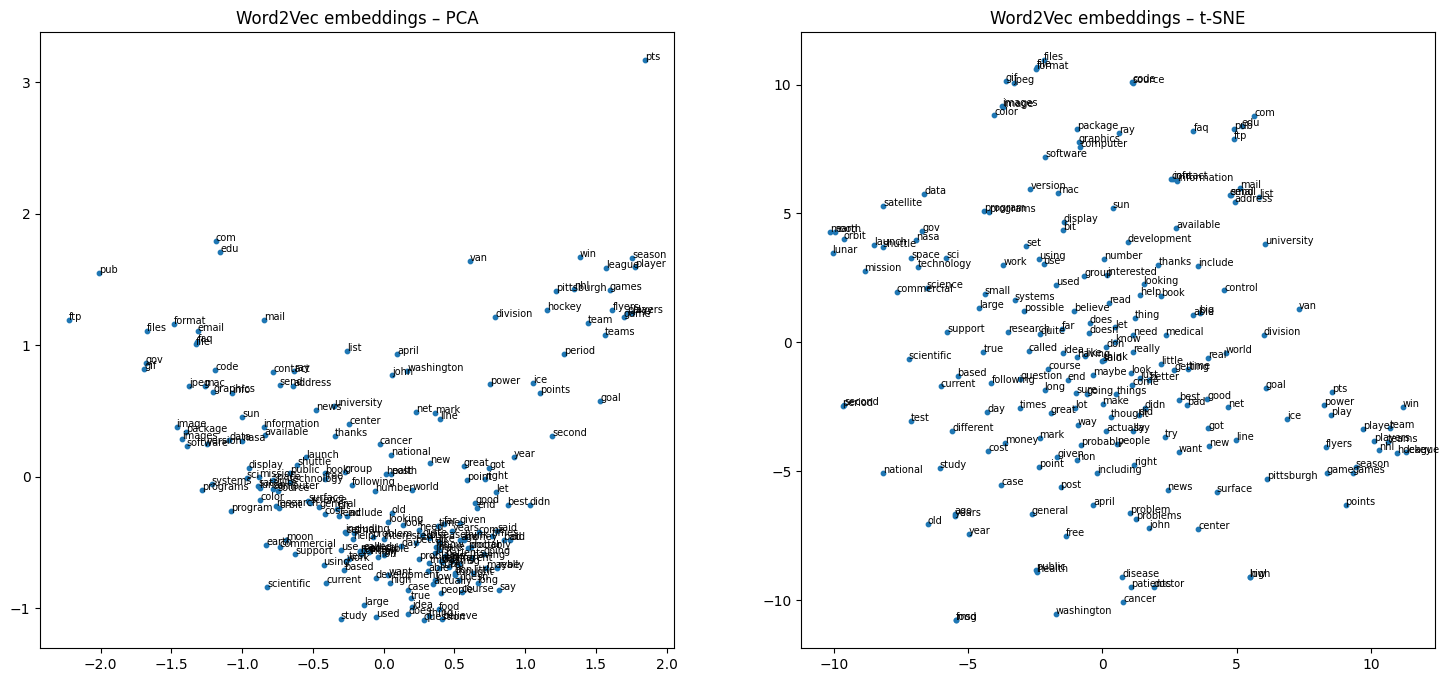

In [12]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
words = list(w2v.wv.index_to_key[:200])
W = np.array([w2v.wv[w] for w in words])
fig, ax = plt.subplots(1, 2, figsize=(18,8))
p = PCA(2).fit_transform(W); t = TSNE(2, perplexity=20, random_state=42, init='pca').fit_transform(W)
for a,(xy,title) in zip(ax, [(p,'PCA'),(t,'t-SNE')]):
    a.scatter(xy[:,0], xy[:,1], s=10)
    for i,w in enumerate(words): a.annotate(w, xy[i], fontsize=7)
    a.set_title(f'Word2Vec embeddings – {title}')
plt.show()   # 📸 screenshot

In [16]:
# Files to upload at https://projector.tensorflow.org  ->  Load
np.savetxt('vectors.tsv', W, delimiter='\t')
open('metadata.tsv','w').write('\n'.join(words))
try:
    from google.colab import files; files.download('vectors.tsv'); files.download('metadata.tsv')
except ImportError: pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Comparative analysis

In [14]:
comp = pd.DataFrame({
 'Aspect':['Representation','Semantic meaning','OOV handling','Context awareness','Dimensionality','Compute cost','Example use'],
 'Traditional (BoW/TF-IDF)':['Sparse count/weight vector','None (word order & meaning ignored)','Unseen word ignored','No','Very high (vocab size)','Very low','Search, baseline classifiers'],
 'Word2Vec / FastText (static)':['Dense learned vector','Good (similar words close)','W2V: fails; FastText: uses subwords','No (one vector per word)','Low (50-300)','Moderate','Similarity, features'],
 'BERT (contextual)':['Dense, depends on sentence','Excellent','WordPiece subwords','Yes','768','High (GPU preferred)','QA, NER, classification']})
display(comp)

,Aspect,Traditional (BoW/TF-IDF),Word2Vec / FastText (static),BERT (contextual)
0,Representation,Sparse count/weight vector,Dense learned vector,"Dense, depends on sentence"
1,Semantic meaning,None (word order & meaning ignored),Good (similar words close),Excellent
2,OOV handling,Unseen word ignored,W2V: fails; FastText: uses subwords,WordPiece subwords
3,Context awareness,No,No (one vector per word),Yes
4,Dimensionality,Very high (vocab size),Low (50-300),768
5,Compute cost,Very low,Moderate,High (GPU preferred)
6,Example use,"Search, baseline classifiers","Similarity, features","QA, NER, classification"
